In [1]:
!pip install pandas numpy matplotlib seaborn openpyxl

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
df = pd.read_csv(
    r'C:\Users\DELL\Downloads\mergers_acquisitions_2019_2026_sample.csv',
    nrows=10000
)
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [7]:
print("Shape:", df.shape)
display(df.head())

Shape: (10000, 23)


,deal_id,announced_date,year,acquirer_name,acquirer_domain,acquirer_country,target_name,target_domain,target_country,target_state,...,stake_pct,deal_status,deal_value_usd,amount_status,cross_border,news_mentions,news_source,news_url,news_excerpt,fliar_profile_url
0,1290404b9ccf,2019-01-01,2019,Blackstone,blackstone.com,United States,Gateway Distriparks,gatewaydistriparks.com,India,Delhi,...,100.0,completed,102000000.0,verified,True,16,business-standard.com,https://www.business-standard.com/article/news...,Logistics major Gateway Distriparks Limited (G...,https://fliarbi.com/company/blackstone/n19ue6r...
1,0955447fd210,2019-01-01,2019,JSW Steel,jswsteel.in,India,Vardhman Industries,vardhmanbrass.com,India,NaN,...,100.0,completed,7620000.0,verified,False,3,NaN,NaN,JSW Steel said it has completed the acquisitio...,https://fliarbi.com/company/jsw-steel/3d07e89o...
2,bbf897d893d1,2019-01-01,2019,Tilney,tilney.co.uk,United Kingdom,Moore Insight,moore-insight.com,United Kingdom,NaN,...,NaN,announced,NaN,not_disclosed,False,2,NaN,NaN,Tilney has acquired the wealth management busi...,https://fliarbi.com/company/tilney/s1l0rz2b0z/...
3,a278085ed9f8,2019-01-02,2019,BrandSafway,brandsafway.com,United States,Cabrillo Hoist,cabrillohoist.com,United States,California,...,NaN,announced,NaN,not_disclosed,False,1,NaN,NaN,"BrandSafway and SafwayAtlantic, a BrandSafway ...",https://fliarbi.com/company/brandsafway/wik0ee...
4,cc404f86a903,2019-01-02,2019,CSS Entertainment,NaN,NaN,Truli Media,NaN,NaN,NaN,...,NaN,announced,NaN,not_disclosed,False,1,variety.com,https://variety.com/2019/digital/news/ashton-k...,"Last fall it picked up Truli Media, a media co...",NaN


In [8]:
for i, col in enumerate(df.columns, start=1):
    print(i, col)

1 deal_id
2 announced_date
3 year
4 acquirer_name
5 acquirer_domain
6 acquirer_country
7 target_name
8 target_domain
9 target_country
10 target_state
11 target_city
12 sector
13 deal_type
14 stake_pct
15 deal_status
16 deal_value_usd
17 amount_status
18 cross_border
19 news_mentions
20 news_source
21 news_url
22 news_excerpt
23 fliar_profile_url


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   deal_id            10000 non-null  object 
 1   announced_date     10000 non-null  object 
 2   year               10000 non-null  int64  
 3   acquirer_name      10000 non-null  object 
 4   acquirer_domain    7495 non-null   object 
 5   acquirer_country   8722 non-null   object 
 6   target_name        10000 non-null  object 
 7   target_domain      6968 non-null   object 
 8   target_country     8535 non-null   object 
 9   target_state       3526 non-null   object 
 10  target_city        6170 non-null   object 
 11  sector             9173 non-null   object 
 12  deal_type          10000 non-null  object 
 13  stake_pct          3465 non-null   float64
 14  deal_status        10000 non-null  object 
 15  deal_value_usd     2461 non-null   float64
 16  amount_status      1000

In [10]:
print("Duplicate deal IDs:", df["deal_id"].duplicated().sum())

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False))

Duplicate deal IDs: 0

Missing values:
deal_value_usd       7539
stake_pct            6535
target_state         6474
target_city          3830
news_url             3614
news_source          3614
target_domain        3032
fliar_profile_url    2762
acquirer_domain      2505
target_country       1465
acquirer_country     1278
sector                827
news_excerpt           12
deal_type               0
announced_date          0
deal_status             0
target_name             0
amount_status           0
cross_border            0
news_mentions           0
acquirer_name           0
year                    0
deal_id                 0
dtype: int64


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   deal_id            10000 non-null  object 
 1   announced_date     10000 non-null  object 
 2   year               10000 non-null  int64  
 3   acquirer_name      10000 non-null  object 
 4   acquirer_domain    7495 non-null   object 
 5   acquirer_country   8722 non-null   object 
 6   target_name        10000 non-null  object 
 7   target_domain      6968 non-null   object 
 8   target_country     8535 non-null   object 
 9   target_state       3526 non-null   object 
 10  target_city        6170 non-null   object 
 11  sector             9173 non-null   object 
 12  deal_type          10000 non-null  object 
 13  stake_pct          3465 non-null   float64
 14  deal_status        10000 non-null  object 
 15  deal_value_usd     2461 non-null   float64
 16  amount_status      1000

In [12]:
print(df["deal_status"].value_counts(dropna=False))

deal_status
announced     6577
completed     2991
pending        365
terminated      67
Name: count, dtype: int64


In [13]:
print(df["deal_type"].value_counts(dropna=False))

deal_type
acquisition    8604
stake           764
merger          632
Name: count, dtype: int64


In [14]:
print(df["deal_type"].value_counts(dropna=False))

deal_type
acquisition    8604
stake           764
merger          632
Name: count, dtype: int64


In [15]:
print(df["sector"].value_counts(dropna=False).head(20))

sector
Business Services                     991
NaN                                   827
Enterprise Applications               570
Financial Services                    553
Food and Agriculture                  366
Fintech                               355
Healthcare                            341
Retail                                309
Energy                                305
Consumer                              285
Real Estate and Construction          243
Telecom                               228
Consumer Goods                        218
Industrial Goods and Manufacturing    205
Media & Entertainment                 181
Healthtech                            173
Enterprise Infrastructure             169
High Tech                             156
Life Sciences                         145
Auto                                  143
Name: count, dtype: int64


In [16]:
print(df["amount_status"].value_counts(dropna=False))

amount_status
not_disclosed    7244
verified         1763
unchecked         698
failed_check      295
Name: count, dtype: int64


In [17]:
print("First deal date:", df["announced_date"].min())
print("Last deal date:", df["announced_date"].max())

print("\nDeals by year:")
print(df["year"].value_counts().sort_index())

First deal date: 2019-01-01
Last deal date: 2021-12-22

Deals by year:
year
2019    2608
2020    2909
2021    4483
Name: count, dtype: int64


In [18]:
yearly_deals = (
    df.groupby("year")
    .agg(
        Total_Deals=("deal_id", "count"),
        Disclosed_Values=("deal_value_usd", "count"),
        Total_Disclosed_Value=("deal_value_usd", "sum")
    )
    .reset_index()
)

display(yearly_deals)

,year,Total_Deals,Disclosed_Values,Total_Disclosed_Value
0,2019,2608,720,7.212398e+11
1,2020,2909,717,7.948027e+11
2,2021,4483,1024,1.026222e+12


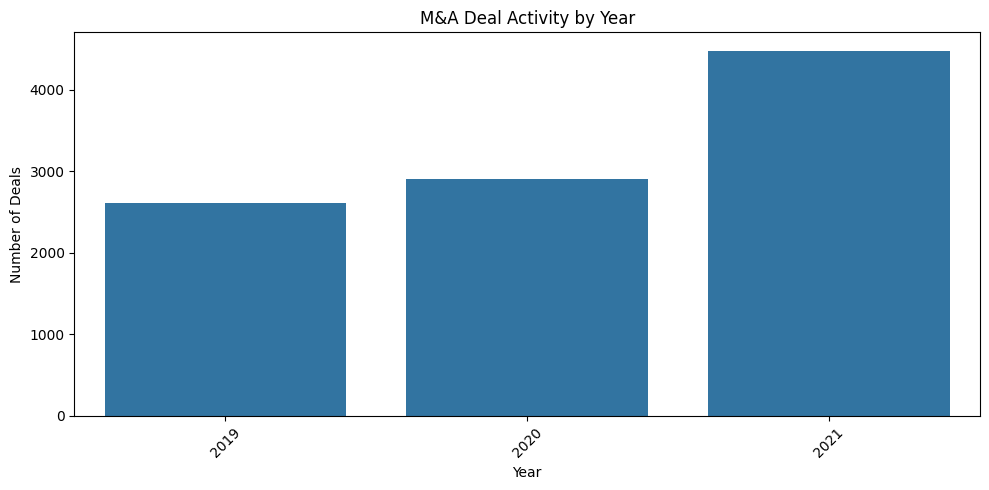

In [19]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=yearly_deals,
    x="year",
    y="Total_Deals"
)

plt.title("M&A Deal Activity by Year")
plt.xlabel("Year")
plt.ylabel("Number of Deals")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
healthcare_sectors = [
    "Healthcare",
    "Healthtech",
    "Life Sciences"
]

healthcare_df = df[
    df["sector"].isin(healthcare_sectors)
].copy()

print("Healthcare-related deals:", len(healthcare_df))

display(
    healthcare_df[
        [
            "announced_date",
            "acquirer_name",
            "target_name",
            "sector",
            "acquirer_country",
            "target_country",
            "deal_type",
            "deal_status",
            "deal_value_usd"
        ]
    ].head(10)
)

Healthcare-related deals: 659


,announced_date,acquirer_name,target_name,sector,acquirer_country,target_country,deal_type,deal_status,deal_value_usd
6,2019-01-02,Faurecia,Clarion,Healthcare,France,Japan,acquisition,completed,1.188000e+09
14,2019-01-03,Bristol-Myers Squibb,Celgene,Healthcare,United States,United States,acquisition,completed,7.400000e+10
17,2019-01-03,Kashiv Pharma,Adello Biologics,Healthcare,United States,United States,acquisition,announced,NaN
21,2019-01-04,Ampliphi Biosciences,C3J Therapeutics,Life Sciences,United States,United States,merger,announced,NaN
24,2019-01-04,Boots,Wiggly-Amps,Healthcare,United Kingdom,United Kingdom,acquisition,announced,NaN
33,2019-01-04,Grupo Aúna,Promotora Médica Las Américas,Healthcare,Peru,Colombia,acquisition,completed,NaN
36,2019-01-04,Keystone Dental,Paltop,Life Sciences,United States,Israel,merger,announced,NaN
49,2019-01-07,Factory-Cro Group,Boston Biomedical Associates,Healthcare,Netherlands,United States,merger,completed,NaN
52,2019-01-07,New Age Beverages Corporation,Morinda,Healthcare,United States,United States,acquisition,completed,8.500000e+07
55,2019-01-07,Shimadzu Medical Systems Usa,Coremedicalimaging,Healthcare,United States,United States,acquisition,announced,NaN


In [21]:
sector_analysis = (
    healthcare_df["sector"]
    .value_counts()
    .reset_index()
)

sector_analysis.columns = ["Sector", "Number_of_Deals"]

display(sector_analysis)

,Sector,Number_of_Deals
0,Healthcare,341
1,Healthtech,173
2,Life Sciences,145


In [22]:
display(
    healthcare_df["deal_status"].value_counts()
)

deal_status
announced     418
completed     220
pending        17
terminated      4
Name: count, dtype: int64

In [23]:
top_acquirers = (
    healthcare_df["acquirer_name"]
    .value_counts()
    .head(10)
    .reset_index()
)

top_acquirers.columns = ["Acquirer", "Number_of_Deals"]

display(top_acquirers)

,Acquirer,Number_of_Deals
0,Sanofi,8
1,KKR,7
2,Hapvida,6
3,Humana,5
4,UnitedHealth Group,5
5,Novartis,5
6,Bristol-Myers Squibb,4
7,LHC Group,4
8,Accenture,3
9,CloudMD,3


In [24]:
disclosed_deals = healthcare_df.dropna(
    subset=["deal_value_usd"]
)

print("Healthcare deals:", len(healthcare_df))
print("Deals with disclosed values:", len(disclosed_deals))

print(
    "Total disclosed deal value (USD):",
    disclosed_deals["deal_value_usd"].sum()
)

print(
    "Average disclosed deal value (USD):",
    disclosed_deals["deal_value_usd"].mean()
)

Healthcare deals: 659
Deals with disclosed values: 215
Total disclosed deal value (USD): 388652758177.0
Average disclosed deal value (USD): 1807687247.3348837


In [25]:
india_healthcare = healthcare_df[
    healthcare_df["target_country"].str.contains(
        "India",
        case=False,
        na=False
    )
].copy()

print("India-related healthcare deals:", len(india_healthcare))

display(
    india_healthcare[
        [
            "acquirer_name",
            "target_name",
            "sector",
            "acquirer_country",
            "target_country",
            "deal_type",
            "deal_status",
            "deal_value_usd"
        ]
    ].head(15)
)

India-related healthcare deals: 34


,acquirer_name,target_name,sector,acquirer_country,target_country,deal_type,deal_status,deal_value_usd
65,Roquette,Crest Cellulose,Healthcare,France,India,acquisition,announced,NaN
357,Goldencross Pharma,Wellthy Therapeutics,Healthtech,India,India,stake,completed,1.260000e+06
533,Everlife,CPC Diagnostics,Healthcare,Singapore,India,stake,announced,NaN
575,Emami,Zandu,Healthcare,India,India,acquisition,completed,9.000000e+07
712,Everstone Group,Sahyadri Hospitals Ltd,Healthcare,India,India,acquisition,completed,NaN
810,"M3 , Inc",Neuroglia Health,Healthtech,Japan,India,acquisition,announced,NaN
874,Asia Healthcare Holdings,Nova IVI Fertility,Healthcare,India,India,acquisition,announced,NaN
1435,Baring Private Equity Asia,CitiusTech,Healthcare,Hong Kong,India,acquisition,completed,1.000000e+09
1617,MUFG,Dr. Reddy's Laboratories,Healthcare,Japan,India,stake,completed,NaN
1744,Hindustan Unilever,Indulekha,Healthcare,India,India,acquisition,completed,NaN


In [26]:
print("Years available:")
print(sorted(df["year"].unique()))

print("\nNumber of deals by year:")
print(df["year"].value_counts().sort_index())

Years available:
[2019, 2020, 2021]

Number of deals by year:
year
2019    2608
2020    2909
2021    4483
Name: count, dtype: int64


In [27]:
import pandas as pd

file_path = r'C:\Users\DELL\Downloads\mergers_acquisitions_2019_2026_sample.csv'

df = pd.read_csv(file_path)

print("Full dataset loaded successfully!")
print("Dataset shape:", df.shape)

Full dataset loaded successfully!
Dataset shape: (30887, 23)


In [28]:
print("Available years:", sorted(df["year"].unique()))

print("\nDeals by year:")
print(df["year"].value_counts().sort_index())


Available years: [2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]

Deals by year:
year
2019    2608
2020    2909
2021    4556
2022    4056
2023    4027
2024    4888
2025    5223
2026    2620
Name: count, dtype: int64


In [29]:
memory = df.memory_usage(deep=True).sum() / (1024**2)

print(f"Memory usage: {memory:.2f} MB")

Memory usage: 44.93 MB


In [32]:
#data coverage
print("Dataset shape:", df.shape)

print("\nAvailable years:")
print(sorted(df["year"].unique()))

print("\nDeals by year:")
display(
    df["year"].value_counts()
    .sort_index()
    .reset_index()
)

Dataset shape: (30887, 23)

Available years:
[2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]

Deals by year:


,year,count
0,2019,2608
1,2020,2909
2,2021,4556
3,2022,4056
4,2023,4027
5,2024,4888
6,2025,5223
7,2026,2620


In [31]:
# data quality
print("Duplicate deal IDs:", df["deal_id"].duplicated().sum())

missing_data = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

display(
    missing_data.sort_values(
        by="Missing_Percentage",
        ascending=False
    )
)

Duplicate deal IDs: 0


,Missing_Count,Missing_Percentage
deal_value_usd,23494,76.064364
target_state,21033,68.096610
stake_pct,19357,62.670379
target_city,12933,41.871985
news_url,10717,34.697446
news_source,10717,34.697446
target_domain,10512,34.033736
fliar_profile_url,9620,31.145789
acquirer_domain,8715,28.215754
target_country,5008,16.213941


In [33]:
healthcare_sectors = [
    "Healthcare",
    "Healthtech",
    "Life Sciences"
]

healthcare_df = df[
    df["sector"].isin(healthcare_sectors)
].copy()

print("Total healthcare-related deals:", len(healthcare_df))

print("\nDeals by sector:")
display(healthcare_df["sector"].value_counts())

print("\nDeals by year:")
display(healthcare_df["year"].value_counts().sort_index())

Total healthcare-related deals: 1877

Deals by sector:


sector
Healthcare       988
Life Sciences    475
Healthtech       414
Name: count, dtype: int64


Deals by year:


year
2019    170
2020    193
2021    301
2022    250
2023    263
2024    250
2025    294
2026    156
Name: count, dtype: int64

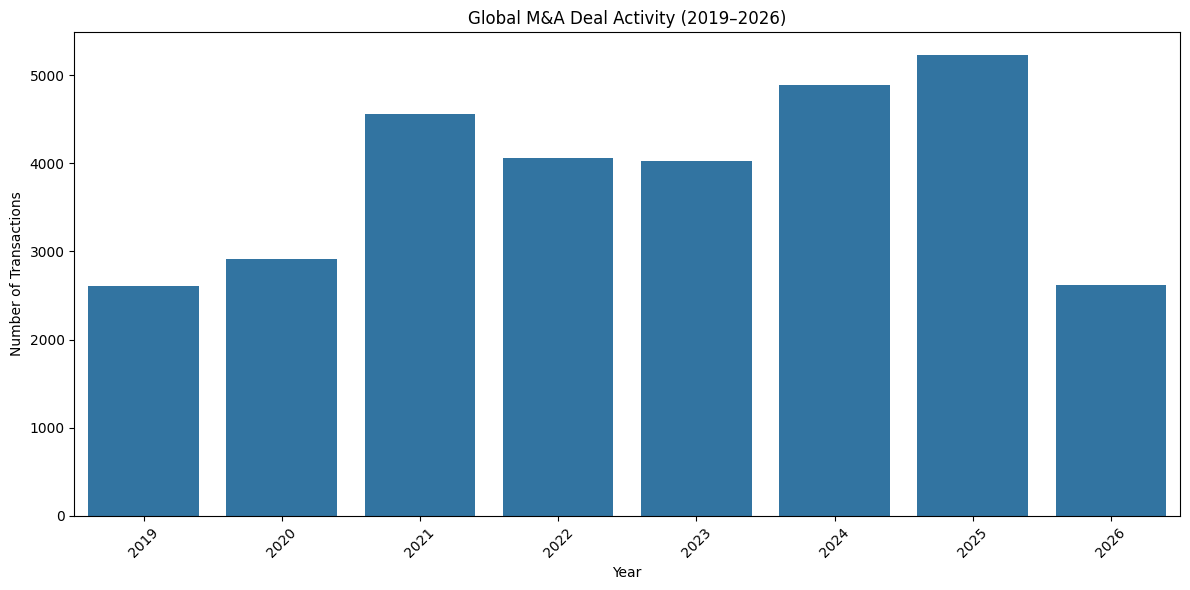

In [34]:
yearly_deals = (
    df.groupby("year")
    .agg(
        Total_Deals=("deal_id", "count"),
        Disclosed_Values=("deal_value_usd", "count"),
        Total_Disclosed_Value=("deal_value_usd", "sum")
    )
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=yearly_deals,
    x="year",
    y="Total_Deals"
)

plt.title("Global M&A Deal Activity (2019–2026)")
plt.xlabel("Year")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [35]:
#Our next analysis will identify healthcare, healthtech and life-sciences transactions across all 30,887 records.

healthcare_sectors = [
    "Healthcare",
    "Healthtech",
    "Life Sciences"
]

healthcare_df = df[
    df["sector"].isin(healthcare_sectors)
].copy()

print("Healthcare-related deals:", len(healthcare_df))

print("\nSector distribution:")
display(healthcare_df["sector"].value_counts())

print("\nHealthcare deals by year:")
display(
    healthcare_df["year"]
    .value_counts()
    .sort_index()
)

Healthcare-related deals: 1877

Sector distribution:


sector
Healthcare       988
Life Sciences    475
Healthtech       414
Name: count, dtype: int64


Healthcare deals by year:


year
2019    170
2020    193
2021    301
2022    250
2023    263
2024    250
2025    294
2026    156
Name: count, dtype: int64

In [36]:
india_healthcare = healthcare_df[
    healthcare_df["target_country"].str.contains(
        "India",
        case=False,
        na=False
    )
].copy()

print("Indian healthcare target deals:", len(india_healthcare))

display(india_healthcare.head(10))

Indian healthcare target deals: 134


,deal_id,announced_date,year,acquirer_name,acquirer_domain,acquirer_country,target_name,target_domain,target_country,target_state,...,stake_pct,deal_status,deal_value_usd,amount_status,cross_border,news_mentions,news_source,news_url,news_excerpt,fliar_profile_url
65,4aa76dcb99e8,2019-01-08,2019,Roquette,roquette.com,France,Crest Cellulose,crestcellulose.com,India,Telangana,...,NaN,announced,NaN,not_disclosed,True,1,NaN,NaN,Hyderabad-based Sathguru Management Consultant...,https://fliarbi.com/company/roquette/31ry406gy...
357,3d50eb3f15de,2019-02-18,2019,Goldencross Pharma,NaN,India,Wellthy Therapeutics,wellthytherapeutics.com,India,Maharashtra,...,11.71,completed,1.260000e+06,unchecked,False,3,franchiseindia.com,https://www.franchiseindia.com/insights/en/art...,Cipla Monday said it has inked a pact to acqui...,NaN
533,ab79b701078d,2019-03-13,2019,Everlife,everlifeasia.com,Singapore,CPC Diagnostics,cpcdiagnostics.in,India,Tamil Nadu,...,NaN,announced,NaN,not_disclosed,True,5,financialexpress.com,https://www.financialexpress.com/business/indu...,Private equity firm Everstone Group’s healthca...,https://fliarbi.com/company/everlife/2diu88ugr...
575,fb42e5f5b180,2019-03-19,2019,Emami,emamiltd.in,India,Zandu,zanducare.com,India,West Bengal,...,72.00,completed,9.000000e+07,verified,False,5,business-standard.com,https://www.business-standard.com/article/news...,Rs 750 crore was the consideration paid by Ema...,https://fliarbi.com/company/emami/1wityh4zsh/?...
712,271cd564e29d,2019-04-07,2019,Everstone Group,everstonegroup.com.au,India,Sahyadri Hospitals Ltd,sahyadrihospitals.com,India,Maharashtra,...,NaN,completed,NaN,not_disclosed,False,9,newsmobile.in,https://www.newsmobile.in/trending-now/eversto...,The Everstone Group has agreed to acquire a co...,https://fliarbi.com/company/everstone-group/1f...
810,ebf7f73e67cd,2019-04-22,2019,"M3 , Inc",NaN,Japan,Neuroglia Health,neurogliahealth.com,India,Karnataka,...,NaN,announced,NaN,not_disclosed,True,1,NaN,NaN,"Japanese healthcare firm M3 , Inc has acquired...",NaN
874,8d873a46ee53,2019-05-02,2019,Asia Healthcare Holdings,NaN,India,Nova IVI Fertility,novaivifertility.com,India,Karnataka,...,100.00,announced,NaN,not_disclosed,False,2,tpg.com,https://www.tpg.com/news-and-insights/asia-hea...,"Asia Healthcare Holdings (AHH), a healthcare o...",NaN
1435,6a92bdaa7396,2019-07-12,2019,Baring Private Equity Asia,NaN,Hong Kong,CitiusTech,citiustech.com,India,New Jersey,...,80.00,completed,1.000000e+09,unchecked,True,4,economictimes.indiatimes.com,https://economictimes.indiatimes.com/industry/...,Mumbai: Baring Private Equity Asia has emerged...,NaN
1617,4086e1c53201,2019-08-06,2019,MUFG,mufg.jp,Japan,Dr. Reddy's Laboratories,drreddys.com,India,Telangana,...,8.41,completed,NaN,not_disclosed,True,2,NaN,NaN,Pharmaceuticals major Dr Reddy's said on Tuesd...,https://fliarbi.com/company/mufg/381l4c5rfe/?u...
1744,ea94323c253b,2019-08-23,2019,Hindustan Unilever,NaN,India,Indulekha,indulekhaonline.com,India,NaN,...,100.00,completed,NaN,failed_check,False,3,NaN,NaN,Around three years after it acquired the hair ...,NaN


In [37]:
print("Dataset shape:", df.shape)

print("Duplicate deal IDs:", df["deal_id"].duplicated().sum())

print("\nMissing values:")
missing_data = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(
    missing_data.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

Dataset shape: (30887, 23)
Duplicate deal IDs: 0

Missing values:


,Missing_Count,Missing_Percentage
deal_value_usd,23494,76.06
target_state,21033,68.10
stake_pct,19357,62.67
target_city,12933,41.87
news_url,10717,34.70
news_source,10717,34.70
target_domain,10512,34.03
fliar_profile_url,9620,31.15
acquirer_domain,8715,28.22
target_country,5008,16.21


In [38]:
#clean and validate data

In [39]:
df_clean = df.copy()

# Convert date column
df_clean["announced_date"] = pd.to_datetime(
    df_clean["announced_date"],
    errors="coerce"
)

# Remove leading and trailing spaces from text columns
text_columns = df_clean.select_dtypes(
    include="object"
).columns

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

# Standardize company names and categorical columns
categorical_columns = [
    "sector",
    "deal_type",
    "deal_status",
    "amount_status"
]

for col in categorical_columns:
    df_clean[col] = df_clean[col].str.strip()

print("Data cleaning completed!")
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

Data cleaning completed!
Original shape: (30887, 23)
Cleaned shape: (30887, 23)


In [40]:
print("Missing dates:", df_clean["announced_date"].isnull().sum())

print("Duplicate IDs:", df_clean["deal_id"].duplicated().sum())

print("\nUnique deal statuses:")
print(df_clean["deal_status"].unique())

print("\nUnique deal types:")
print(df_clean["deal_type"].unique())

print("\nUnique sectors:")
print(df_clean["sector"].nunique())

Missing dates: 0
Duplicate IDs: 0

Unique deal statuses:
['completed' 'announced' 'pending' 'terminated']

Unique deal types:
['acquisition' 'merger' 'stake']

Unique sectors:
3991


In [41]:
quality_report = pd.DataFrame({
    "Column": df_clean.columns,
    "Data_Type": df_clean.dtypes.astype(str).values,
    "Missing_Count": df_clean.isnull().sum().values,
    "Missing_Percentage": (
        df_clean.isnull().mean().values * 100
    ).round(2)
})

display(quality_report)

,Column,Data_Type,Missing_Count,Missing_Percentage
0,deal_id,object,0,0.00
1,announced_date,datetime64[ns],0,0.00
2,year,int64,0,0.00
3,acquirer_name,object,0,0.00
4,acquirer_domain,object,8715,28.22
5,acquirer_country,object,4599,14.89
6,target_name,object,0,0.00
7,target_domain,object,10512,34.03
8,target_country,object,5008,16.21
9,target_state,object,21033,68.10


In [42]:
print(
    df_clean["sector"]
    .value_counts(dropna=False)
    .head(30)
)


sector
Business Services                     2930
NaN                                   2754
Financial Services                    1759
Enterprise Applications               1549
Food and Agriculture                  1082
Fintech                               1064
Energy                                1019
Healthcare                             988
Retail                                 876
Consumer                               863
Real Estate and Construction           795
Industrial Goods and Manufacturing     672
Consumer Goods                         665
Telecom                                575
Enterprise Infrastructure              544
Life Sciences                          475
High Tech                              470
Media & Entertainment                  469
Auto                                   435
Healthtech                             414
Transportation and Logistics           382
Chemicals and Materials                352
Mining                                 346
Envi

In [43]:
print(
    df_clean["sector"]
    .value_counts()
    .tail(20)
)

sector
Cleanroom and Laboratory Cleaning         1
Automotive and Industrial Supplier        1
Hvac Service Provider                     1
Mining Services                           1
Environmental and Industrial Services     1
Bingo                                     1
Product Life-cycle Management Services    1
Industrial and Utilities                  1
Front End Services                        1
ERP Software Solutions                    1
Aerospace & Defense Supply Chain          1
Digital Commerce Agency                   1
Sustainability Data Mining                1
Wood Processing Industry                  1
Tech Payments                             1
Meat Products                             1
Custom Mechanical Solutions               1
Property Tax Management                   1
Online Marketplace Operator               1
Production of Cleavage Parts              1
Name: count, dtype: int64


In [44]:
print("Total unique sectors:", df_clean["sector"].nunique())

print("\nSample sector names:")

for sector in df_clean["sector"].dropna().unique()[:50]:
    print(sector)

Total unique sectors: 3991

Sample sector names:
Transportation and Logistics
Chemicals and Materials
Financial Services
Real Estate and Construction
Wind Energy
Healthcare
Education
Pharmacy Technology
Food and Agriculture
Auto
Mining
Business Services
Enterprise Applications
Investment Industry
Retail
Life Sciences
Industrial Goods and Manufacturing
Consumer Goods
Scaffolding & Access
Energy Tech
Fintech
Airports
Animal Health
Aircraft Leasing
Scaffolding
Consumer
Energy Services
Payments
Energy
Electronics Manufacturing, Pcb Assembly
ECOMMERCE
Conglomerates
High Tech
Architecture/design
Reinsurance
Fleet Management and Leasing
Environment
Packaging
Pest Control Services
Process Measurement and Instrumentation
Solar Energy
Semiconductors
Healthtech
Travel and Hospitality
Publishing
Telecom
Media & Entertainment
Edtech
Aerospace, Maritime and Defense Tech
Travel


In [45]:
keywords = [
    "health",
    "medical",
    "diagnostic",
    "genom",
    "biotech",
    "pharma",
    "laboratory",
    "life science",
    "clinical",
    "hospital",
    "medicine",
    "drug",
    "therapeutic",
    "pathology",
    "molecular",
    "veterinary"
]

sector_list = df_clean["sector"].dropna().unique()

relevant_sectors = sorted([
    sector for sector in sector_list
    if any(keyword in sector.lower() for keyword in keywords)
])

print("Potentially relevant sector labels:", len(relevant_sectors))

for sector in relevant_sectors:
    print(sector)

Potentially relevant sector labels: 247
Aesthetic Medicine
Ai-driven Imaging Diagnostics
Ambulatory Mental Healthcare Services
Anatomic Pathology Consumables
Animal Health
Animal Health & Nutrition Solutions
Animal Health Products Distribution
Animal Medicine
Anti-cancer Drug Development
B2B Wholesale Platforms for Pharmacies
Bar Supplies and Hospitality Products
Behavioral Health Pharmacy
Bioanalytical Laboratory Business
Biomedical
Biopharma
Biopharmaceutical
Biopharmaceuticals
Biotech
Biotech / Immuno‑oncology
Biotech and Pharmaceutical Supplier
Biotechnology
Calibration Laboratory
Cannabis Testing Laboratory
Cleanroom and Laboratory Cleaning
Clinical Analysis Services
Clinical Biometrics
Clinical Research
Clinical Site
Clinical-stage Biopharmaceutical
Clinical-stage Oncology
Community Pharmacy
Concierge Medicine Practice
Consumer Health
Consumer Health Products
Consumer Healthcare
Corporate Healthcare Provision
Cosmetic and Parapharmaceutical Products
Csr Diagnostics
Dental Health


In [46]:
relevant_sector_counts = (
    df_clean[df_clean["sector"].isin(relevant_sectors)]
    ["sector"]
    .value_counts()
    .reset_index()
)

relevant_sector_counts.columns = [
    "Sector",
    "Number_of_Deals"
]

display(relevant_sector_counts)

,Sector,Number_of_Deals
0,Healthcare,988
1,Life Sciences,475
2,Healthtech,414
3,Travel and Hospitality,281
4,Travel and Hospitality Tech,62
...,...,...
242,Clinical-stage Oncology,1
243,Health Supplements,1
244,Cleanroom and Laboratory Cleaning,1
245,Diagnostic Lab,1


In [47]:
def classify_sector(sector):
    s = str(sector).lower()

    # Exclude obvious unrelated or misleading matches
    exclude_keywords = [
        "hospitality",
        "calibration laboratory",
        "cleanroom and laboratory cleaning",
        "food safety analysis",
        "medical and industrial",
        "property development"
    ]

    if any(word in s for word in exclude_keywords):
        return "Exclude / Review"

    # Core healthcare and life sciences
    core_keywords = [
        "healthcare", "health care", "healthtech", "health tech",
        "health technology", "health services", "health system",
        "health it", "health insurance", "health plan",
        "life science", "biotech", "biopharma", "biopharmaceutical",
        "pharma", "pharmaceutical", "diagnostic", "diagnostics",
        "genom", "medical", "clinical", "hospital",
        "pathology", "oncolog", "therapeutic", "telemedicine",
        "digital health", "molecular", "precision medicine",
        "in vitro", "primary healthcare", "mental health"
    ]

    if any(word in s for word in core_keywords):
        return "Core Healthcare & Life Sciences"

    # Healthcare-adjacent industries
    adjacent_keywords = [
        "animal health", "veterinary", "pet health",
        "pharmacy", "laboratory", "lab services",
        "wellness", "fitness", "nutrition",
        "occupational health", "cannabis",
        "health supplements", "health brokerage",
        "healthcare consulting", "healthcare recruitment"
    ]

    if any(word in s for word in adjacent_keywords):
        return "Healthcare-Adjacent"

    return "Exclude / Review"


df_clean["sector_category"] = df_clean["sector"].apply(classify_sector)

In [48]:
# Number of deals in each category
category_summary = (
    df_clean["sector_category"]
    .value_counts()
    .reset_index()
)

category_summary.columns = ["Category", "Number_of_Deals"]

category_summary["Percentage"] = (
    category_summary["Number_of_Deals"] /
    len(df_clean) * 100
).round(2)

display(category_summary)

,Category,Number_of_Deals,Percentage
0,Exclude / Review,28596,92.58
1,Core Healthcare & Life Sciences,2218,7.18
2,Healthcare-Adjacent,73,0.24


In [49]:
sector_summary = (
    df_clean.groupby(
        ["sector_category", "sector"],
        dropna=False
    )
    .size()
    .reset_index(name="Number_of_Deals")
    .sort_values(
        ["sector_category", "Number_of_Deals"],
        ascending=[True, False]
    )
)

display(sector_summary.head(100))

,sector_category,sector,Number_of_Deals
54,Core Healthcare & Life Sciences,Healthcare,988
99,Core Healthcare & Life Sciences,Life Sciences,475
90,Core Healthcare & Life Sciences,Healthtech,414
154,Core Healthcare & Life Sciences,Pharmaceuticals,30
12,Core Healthcare & Life Sciences,Biotechnology,28
...,...,...,...
66,Core Healthcare & Life Sciences,Healthcare Financing,1
67,Core Healthcare & Life Sciences,Healthcare Food,1
69,Core Healthcare & Life Sciences,Healthcare IT Consulting,1
70,Core Healthcare & Life Sciences,Healthcare Infrastructure,1


In [50]:
category_summary = (
    df_clean.groupby("sector_category")
    .size()
    .reset_index(name="Number_of_Deals")
)

category_summary["Percentage"] = (
    category_summary["Number_of_Deals"] / len(df_clean) * 100
).round(2)

display(category_summary)

,sector_category,Number_of_Deals,Percentage
0,Core Healthcare & Life Sciences,2218,7.18
1,Exclude / Review,28596,92.58
2,Healthcare-Adjacent,73,0.24


In [51]:
core_sector_summary = (
    df_clean[
        df_clean["sector_category"] == "Core Healthcare & Life Sciences"
    ]
    .groupby("sector")
    .size()
    .reset_index(name="Number_of_Deals")
    .sort_values("Number_of_Deals", ascending=False)
)

display(core_sector_summary.head(30))

,sector,Number_of_Deals
54,Healthcare,988
99,Life Sciences,475
90,Healthtech,414
154,Pharmaceuticals,30
12,Biotechnology,28
139,Pharmaceutical,22
29,Diagnostics,15
7,Biopharmaceutical,12
109,Medical Devices,6
156,Pharmacy,5


In [52]:
core_sector_summary["Percentage"] = (
    core_sector_summary["Number_of_Deals"] / 2218 * 100
).round(2)

display(core_sector_summary.head(30))

,sector,Number_of_Deals,Percentage
54,Healthcare,988,44.54
99,Life Sciences,475,21.42
90,Healthtech,414,18.67
154,Pharmaceuticals,30,1.35
12,Biotechnology,28,1.26
139,Pharmaceutical,22,0.99
29,Diagnostics,15,0.68
7,Biopharmaceutical,12,0.54
109,Medical Devices,6,0.27
156,Pharmacy,5,0.23


In [53]:
healthcare_df = df_clean[
    df_clean["sector_category"] == "Core Healthcare & Life Sciences"
].copy()

yearly_deals = (
    healthcare_df.groupby("year")
    .size()
    .reset_index(name="Healthcare_Deals")
)

display(yearly_deals)

,year,Healthcare_Deals
0,2019,200
1,2020,222
2,2021,345
3,2022,292
4,2023,306
5,2024,299
6,2025,355
7,2026,199


In [54]:
yearly_deals["YoY_Growth_%"] = (
    yearly_deals["Healthcare_Deals"]
    .pct_change() * 100
).round(2)

display(yearly_deals)

,year,Healthcare_Deals,YoY_Growth_%
0,2019,200,NaN
1,2020,222,11.00
2,2021,345,55.41
3,2022,292,-15.36
4,2023,306,4.79
5,2024,299,-2.29
6,2025,355,18.73
7,2026,199,-43.94


In [55]:
yearly_deals["YoY_Growth_%"] = (
    yearly_deals["Healthcare_Deals"]
    .pct_change() * 100
).round(2)

display(yearly_deals)

,year,Healthcare_Deals,YoY_Growth_%
0,2019,200,NaN
1,2020,222,11.00
2,2021,345,55.41
3,2022,292,-15.36
4,2023,306,4.79
5,2024,299,-2.29
6,2025,355,18.73
7,2026,199,-43.94


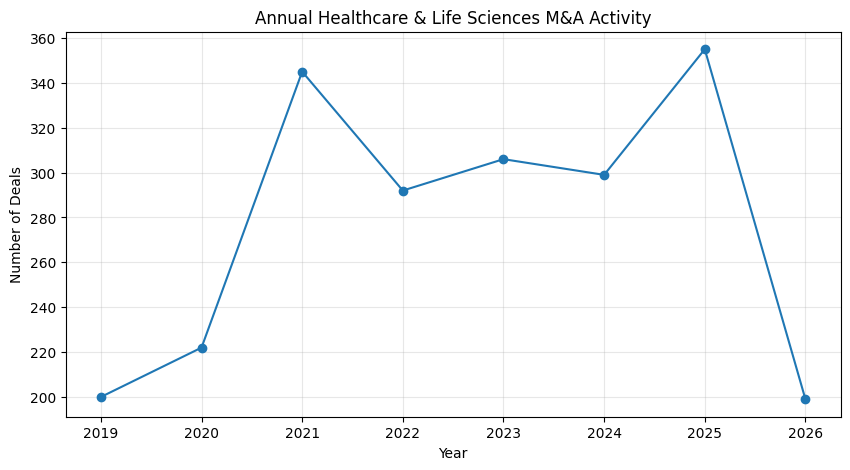

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    yearly_deals["year"],
    yearly_deals["Healthcare_Deals"],
    marker="o"
)

plt.title("Annual Healthcare & Life Sciences M&A Activity")
plt.xlabel("Year")
plt.ylabel("Number of Deals")
plt.xticks(yearly_deals["year"])
plt.grid(True, alpha=0.3)

plt.show()

In [57]:
def identify_subsector(sector):
    s = str(sector).lower()

    if any(x in s for x in [
        "diagnostic", "genom", "molecular", "pathology"
    ]):
        return "Diagnostics & Molecular Testing"

    elif any(x in s for x in [
        "biotech", "biopharma", "biopharmaceutical"
    ]):
        return "Biotechnology & Biopharma"

    elif "life science" in s:
        return "Life Sciences"

    elif any(x in s for x in [
        "clinical research", "clinical analysis",
        "clinical biometrics"
    ]):
        return "Clinical Research"

    else:
        return "Other Healthcare"

In [58]:
healthcare_df["subsector"] = (
    healthcare_df["sector"].apply(identify_subsector)
)

In [60]:
subsector_trend = (
    healthcare_df.groupby(["year", "subsector"])
    .size()
    .reset_index(name="Number_of_Deals")
)

subsector_pivot = subsector_trend.pivot(
    index="year",
    columns="subsector",
    values="Number_of_Deals"
).fillna(0).astype(int)

display(subsector_pivot)

subsector,Biotechnology & Biopharma,Clinical Research,Diagnostics & Molecular Testing,Life Sciences,Other Healthcare
year,,,,,
2019,4,0,3,37,156
2020,4,0,2,43,173
2021,8,1,5,66,265
2022,6,0,7,59,220
2023,6,0,5,87,208
2024,8,0,7,63,221
2025,9,1,5,73,267
2026,8,1,2,50,138


In [61]:
display(
    healthcare_df["subsector"]
    .value_counts()
    .reset_index()
    .rename(columns={
        "subsector": "Subsector",
        "count": "Number_of_Deals"
    })
)

,Subsector,Number_of_Deals
0,Other Healthcare,1648
1,Life Sciences,478
2,Biotechnology & Biopharma,53
3,Diagnostics & Molecular Testing,36
4,Clinical Research,3


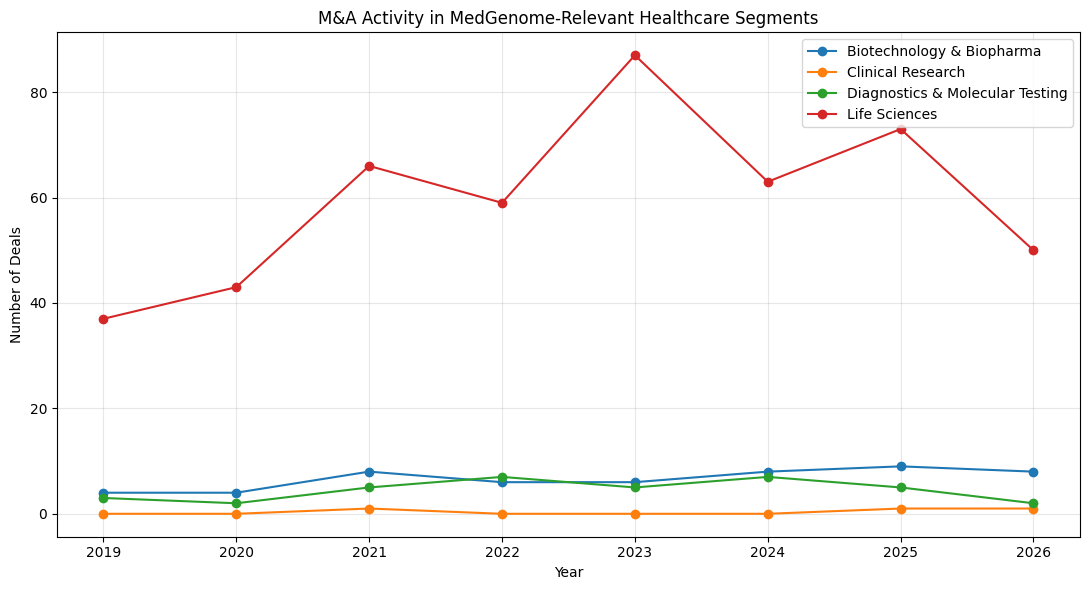

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

for column in [
    "Biotechnology & Biopharma",
    "Clinical Research",
    "Diagnostics & Molecular Testing",
    "Life Sciences"
]:
    plt.plot(
        subsector_pivot.index,
        subsector_pivot[column],
        marker="o",
        label=column
    )

plt.title("M&A Activity in MedGenome-Relevant Healthcare Segments")
plt.xlabel("Year")
plt.ylabel("Number of Deals")
plt.xticks(subsector_pivot.index)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [63]:
india_healthcare = healthcare_df[
    (healthcare_df["acquirer_country"].str.contains(
        "India", case=False, na=False
    )) |
    (healthcare_df["target_country"].str.contains(
        "India", case=False, na=False
    ))
].copy()

print("India-related healthcare deals:", len(india_healthcare))

print("\nDeals by target country:")
display(
    india_healthcare["target_country"]
    .value_counts()
    .head(15)
)

print("\nDeals by acquirer country:")
display(
    india_healthcare["acquirer_country"]
    .value_counts()
    .head(15)
)

India-related healthcare deals: 224

Deals by target country:


target_country
India             169
United States      16
Germany             5
France              4
Switzerland         3
Singapore           2
Belgium             2
Brazil              1
Canada              1
Hungary             1
United Kingdom      1
Australia           1
South Africa        1
Nigeria             1
Italy               1
Name: count, dtype: int64


Deals by acquirer country:


acquirer_country
India             164
United States      15
Japan               5
France              3
Hong Kong           3
Singapore           2
Canada              2
Malaysia            2
Switzerland         1
Ireland             1
United Kingdom      1
Netherlands         1
Germany             1
Sweden              1
China               1
Name: count, dtype: int64

In [64]:
print("Cross-border values:")
display(india_healthcare["cross_border"].value_counts(dropna=False))

print("\nDeal status:")
display(india_healthcare["deal_status"].value_counts(dropna=False))

Cross-border values:


cross_border
False    139
True      85
Name: count, dtype: int64


Deal status:


deal_status
announced     137
completed      81
pending         5
terminated      1
Name: count, dtype: int64

In [65]:
india_healthcare["Indian_Acquirer"] = (
    india_healthcare["acquirer_country"]
    .str.strip().str.lower().eq("india")
)

india_healthcare["Indian_Target"] = (
    india_healthcare["target_country"]
    .str.strip().str.lower().eq("india")
)

def transaction_type(row):
    if row["Indian_Acquirer"] and row["Indian_Target"]:
        return "Domestic"
    elif row["Indian_Acquirer"] and not row["Indian_Target"]:
        return "Indian Acquirer - Foreign Target"
    elif not row["Indian_Acquirer"] and row["Indian_Target"]:
        return "Foreign Acquirer - Indian Target"
    else:
        return "Other / Incomplete"

india_healthcare["Transaction_Type"] = (
    india_healthcare.apply(transaction_type, axis=1)
)

display(
    india_healthcare["Transaction_Type"]
    .value_counts()
    .reset_index()
)

,Transaction_Type,count
0,Domestic,109
1,Foreign Acquirer - Indian Target,60
2,Indian Acquirer - Foreign Target,55


In [66]:
print("Top 15 Acquirers:")

display(
    india_healthcare["acquirer_name"]
    .value_counts()
    .head(15)
    .reset_index()
    .rename(columns={
        "acquirer_name": "Acquirer",
        "count": "Number_of_Deals"
    })
)

Top 15 Acquirers:


,Acquirer,Number_of_Deals
0,Torrent Pharma,10
1,Lupin Limited,8
2,Mankind Pharma,8
3,Senores Pharmaceuticals,5
4,Indegene,5
5,Hindustan Unilever,4
6,MediBuddy,4
7,Flipkart,4
8,KKR,4
9,ChrysCapital,4


In [67]:
print("Top 15 Target Companies:")

display(
    india_healthcare["target_name"]
    .value_counts()
    .head(15)
    .reset_index()
    .rename(columns={
        "target_name": "Target",
        "count": "Number_of_Deals"
    })
)

Top 15 Target Companies:


,Target,Number_of_Deals
0,Dr. Reddy's Laboratories,5
1,Boehringer Ingelheim,3
2,Thyrocare,2
3,Wockhardt,2
4,Rubicon,2
5,Indegene,2
6,Park Medi World Limited,2
7,La Renon,2
8,Granules India,2
9,AIG Hospitals,2


In [68]:
indian_targets = india_healthcare[
    india_healthcare["Indian_Target"] == True
]

display(
    indian_targets["target_name"]
    .value_counts()
    .head(20)
    .reset_index()
    .rename(columns={
        "target_name": "Indian_Target",
        "count": "Number_of_Deals"
    })
)

,Indian_Target,Number_of_Deals
0,Dr. Reddy's Laboratories,5
1,Indegene,2
2,Granules India,2
3,API Holdings,2
4,Indira IVF Hospital,2
5,Thyrocare,2
6,Rubicon,2
7,La Renon,2
8,Wockhardt,2
9,Park Medi World Limited,2


In [69]:
display(
    india_healthcare["acquirer_name"]
    .value_counts()
    .head(15)
    .rename_axis("Acquirer")
    .reset_index(name="Number_of_Deals")
)

,Acquirer,Number_of_Deals
0,Torrent Pharma,10
1,Lupin Limited,8
2,Mankind Pharma,8
3,Senores Pharmaceuticals,5
4,Indegene,5
5,Hindustan Unilever,4
6,MediBuddy,4
7,Flipkart,4
8,KKR,4
9,ChrysCapital,4


In [70]:
display(
    india_healthcare["target_name"]
    .value_counts()
    .head(15)
    .rename_axis("Target")
    .reset_index(name="Number_of_Deals")
)

,Target,Number_of_Deals
0,Dr. Reddy's Laboratories,5
1,Boehringer Ingelheim,3
2,Thyrocare,2
3,Wockhardt,2
4,Rubicon,2
5,Indegene,2
6,Park Medi World Limited,2
7,La Renon,2
8,Granules India,2
9,AIG Hospitals,2


In [71]:
display(
    indian_targets["target_name"]
    .value_counts()
    .head(20)
    .rename_axis("Indian_Target")
    .reset_index(name="Number_of_Deals")
)

,Indian_Target,Number_of_Deals
0,Dr. Reddy's Laboratories,5
1,Indegene,2
2,Granules India,2
3,API Holdings,2
4,Indira IVF Hospital,2
5,Thyrocare,2
6,Rubicon,2
7,La Renon,2
8,Wockhardt,2
9,Park Medi World Limited,2


In [72]:
medgenome_deals = india_healthcare[
    india_healthcare["acquirer_name"]
    .str.contains("MedGenome", case=False, na=False)
]

display(
    medgenome_deals[
        [
            "announced_date",
            "acquirer_name",
            "target_name",
            "target_country",
            "sector",
            "deal_type",
            "deal_status",
            "deal_value_usd"
        ]
    ]
)

,announced_date,acquirer_name,target_name,target_country,sector,deal_type,deal_status,deal_value_usd
9614,2021-11-24,MedGenome,Trident Diagnostics and Healthcare Pvt Ltd,India,Diagnostics and Radiology,acquisition,completed,NaN
15602,2023-05-30,MedGenome,Prognosis Laboratories,NaN,Diagnostic Services,acquisition,completed,NaN
20713,2024-07-10,MedGenome,GenX Diagnostics,India,Diagnostics,stake,announced,NaN


In [73]:
display(
    indian_targets["target_name"]
    .value_counts()
    .head(20)
    .rename_axis("Indian_Target")
    .reset_index(name="Number_of_Deals")
)

,Indian_Target,Number_of_Deals
0,Dr. Reddy's Laboratories,5
1,Indegene,2
2,Granules India,2
3,API Holdings,2
4,Indira IVF Hospital,2
5,Thyrocare,2
6,Rubicon,2
7,La Renon,2
8,Wockhardt,2
9,Park Medi World Limited,2


In [74]:
print("Deal value availability:")

display(
    india_healthcare["amount_status"]
    .value_counts(dropna=False)
    .reset_index()
)

print("\nMissing deal values:")

print(
    "Missing:",
    india_healthcare["deal_value_usd"].isna().sum()
)

print(
    "Available:",
    india_healthcare["deal_value_usd"].notna().sum()
)

Deal value availability:


,amount_status,count
0,not_disclosed,117
1,verified,75
2,unchecked,20
3,failed_check,12



Missing deal values:
Missing: 129
Available: 95


In [75]:
print("Deal value availability:")

display(
    india_healthcare["amount_status"]
    .value_counts(dropna=False)
    .reset_index()
)

print("\nMissing deal values:")

print(
    "Missing:",
    india_healthcare["deal_value_usd"].isna().sum()
)

print(
    "Available:",
    india_healthcare["deal_value_usd"].notna().sum()
)

Deal value availability:


,amount_status,count
0,not_disclosed,117
1,verified,75
2,unchecked,20
3,failed_check,12



Missing deal values:
Missing: 129
Available: 95


In [76]:
largest_deals = disclosed_deals.sort_values(
    "deal_value_usd",
    ascending=False
)

display(
    largest_deals[
        [
            "announced_date",
            "acquirer_name",
            "target_name",
            "sector",
            "deal_value_usd",
            "deal_status"
        ]
    ].head(15)
)

,announced_date,acquirer_name,target_name,sector,deal_value_usd,deal_status
14,2019-01-03,Bristol-Myers Squibb,Celgene,Healthcare,7.400000e+10,completed
67,2019-01-08,Takeda Pharmaceutical,Shire,Healthcare,5.842000e+10,completed
9967,2021-12-20,Oracle,Cerner,Healthtech,2.830000e+10,completed
4137,2020-08-05,Teladoc Health,Livongo,Healthtech,1.800000e+10,completed
4105,2020-08-02,Siemens Healthineers,Varian,Healthcare,1.640000e+10,completed
4642,2020-10-05,Bristol-Myers Squibb,MyoKardia,Life Sciences,1.310000e+10,announced
8945,2021-09-30,Merck,Acceleron Pharma,Healthcare,1.150000e+10,completed
2346,2019-11-24,Novartis,The Medicines Company,Healthcare,9.700000e+09,announced
6909,2021-04-27,Humana,Kindredathome.Com,Healthcare,8.100000e+09,announced
5589,2021-01-06,UnitedHealth Group,Change Healthcare,Healthtech,7.840000e+09,completed


In [77]:
pd.crosstab(
    india_healthcare["amount_status"],
    india_healthcare["deal_value_usd"].notna(),
    margins=True
)

deal_value_usd,False,True,All
amount_status,,,
failed_check,12,0,12
not_disclosed,117,0,117
unchecked,0,20,20
verified,0,75,75
All,129,95,224


In [78]:
verified_deals = india_healthcare[
    (india_healthcare["amount_status"] == "verified") &
    (india_healthcare["deal_value_usd"].notna())
].copy()

print("Verified transactions:", len(verified_deals))

display(
    verified_deals["deal_value_usd"].describe()
)

Verified transactions: 75


count    7.500000e+01
mean     3.017632e+08
std      8.622078e+08
min      2.160000e+06
25%      1.237680e+07
50%      4.716000e+07
75%      1.818000e+08
max      5.000000e+09
Name: deal_value_usd, dtype: float64

In [79]:
display(
    verified_deals.nlargest(15, "deal_value_usd")[
        [
            "announced_date",
            "acquirer_name",
            "target_name",
            "sector",
            "deal_value_usd",
            "deal_status"
        ]
    ]
)

,announced_date,acquirer_name,target_name,sector,deal_value_usd,deal_status
17039,2023-09-30,Daiichi-Sankyo,Ranbaxy Laboratories,Healthcare,5.000000e+09,announced
21135,2024-08-05,Blackstone,Aster DM Healthcare,Healthcare,5.000000e+09,announced
25533,2025-06-29,Torrent Pharma,JB,Healthcare,2.340000e+09,completed
19941,2024-05-14,Mankind Pharma,Bharat Serums and Vaccines,Healthcare,1.635600e+09,completed
17526,2023-11-08,Hong Leong Group,Columbia Asia,Healthcare,1.200000e+09,completed
16319,2023-07-28,BPEA,Indira IVF Hospital,Healthcare,6.480000e+08,announced
7572,2021-06-25,API Holdings,Thyrocare,Healthcare,6.130000e+08,completed
23140,2025-01-08,Intas,Coherus Biosciences,Healthcare,5.584000e+08,announced
13157,2022-09-28,KKR,JB Chemicals,Pharmaceuticals,3.720000e+08,announced
117,2019-01-14,Hindustan Unilever,GlaxoSmithKline Consumer Healthcare,Consumer Healthcare,3.654000e+08,completed


In [80]:
print("India healthcare dataset shape:", india_healthcare.shape)

print("\nVerified deals shape:", verified_deals.shape)

print("\nCountries in verified deals:")

display(
    verified_deals[
        ["acquirer_country", "target_country"]
    ].head(20)
)

India healthcare dataset shape: (224, 28)

Verified deals shape: (75, 28)

Countries in verified deals:


,acquirer_country,target_country
117,India,India
575,India,India
1855,India,Switzerland
2055,China,India
2512,India,India
3424,India,United Kingdom
3986,Germany,India
5156,India,India
5904,United States,India
6392,India,India


In [81]:
india_verified_deals = india_healthcare[
    (india_healthcare["amount_status"] == "verified") &
    (india_healthcare["deal_value_usd"].notna())
].copy()

print("Verified India-related deals:",
      len(india_verified_deals))

display(
    india_verified_deals.nlargest(
        15, "deal_value_usd"
    )[
        [
            "announced_date",
            "acquirer_name",
            "target_name",
            "acquirer_country",
            "target_country",
            "sector",
            "deal_value_usd",
            "deal_status"
        ]
    ]
)

Verified India-related deals: 75


,announced_date,acquirer_name,target_name,acquirer_country,target_country,sector,deal_value_usd,deal_status
17039,2023-09-30,Daiichi-Sankyo,Ranbaxy Laboratories,Japan,India,Healthcare,5.000000e+09,announced
21135,2024-08-05,Blackstone,Aster DM Healthcare,United States,India,Healthcare,5.000000e+09,announced
25533,2025-06-29,Torrent Pharma,JB,India,India,Healthcare,2.340000e+09,completed
19941,2024-05-14,Mankind Pharma,Bharat Serums and Vaccines,India,India,Healthcare,1.635600e+09,completed
17526,2023-11-08,Hong Leong Group,Columbia Asia,Malaysia,India,Healthcare,1.200000e+09,completed
16319,2023-07-28,BPEA,Indira IVF Hospital,Sweden,India,Healthcare,6.480000e+08,announced
7572,2021-06-25,API Holdings,Thyrocare,India,India,Healthcare,6.130000e+08,completed
23140,2025-01-08,Intas,Coherus Biosciences,India,United States,Healthcare,5.584000e+08,announced
13157,2022-09-28,KKR,JB Chemicals,United States,India,Pharmaceuticals,3.720000e+08,announced
117,2019-01-14,Hindustan Unilever,GlaxoSmithKline Consumer Healthcare,India,India,Consumer Healthcare,3.654000e+08,completed


In [82]:
display(
    verified_deals.nlargest(15, "deal_value_usd")[
        [
            "announced_date",
            "acquirer_name",
            "target_name",
            "acquirer_country",
            "target_country",
            "sector",
            "deal_value_usd",
            "deal_status"
        ]
    ]
)

,announced_date,acquirer_name,target_name,acquirer_country,target_country,sector,deal_value_usd,deal_status
17039,2023-09-30,Daiichi-Sankyo,Ranbaxy Laboratories,Japan,India,Healthcare,5.000000e+09,announced
21135,2024-08-05,Blackstone,Aster DM Healthcare,United States,India,Healthcare,5.000000e+09,announced
25533,2025-06-29,Torrent Pharma,JB,India,India,Healthcare,2.340000e+09,completed
19941,2024-05-14,Mankind Pharma,Bharat Serums and Vaccines,India,India,Healthcare,1.635600e+09,completed
17526,2023-11-08,Hong Leong Group,Columbia Asia,Malaysia,India,Healthcare,1.200000e+09,completed
16319,2023-07-28,BPEA,Indira IVF Hospital,Sweden,India,Healthcare,6.480000e+08,announced
7572,2021-06-25,API Holdings,Thyrocare,India,India,Healthcare,6.130000e+08,completed
23140,2025-01-08,Intas,Coherus Biosciences,India,United States,Healthcare,5.584000e+08,announced
13157,2022-09-28,KKR,JB Chemicals,United States,India,Pharmaceuticals,3.720000e+08,announced
117,2019-01-14,Hindustan Unilever,GlaxoSmithKline Consumer Healthcare,India,India,Consumer Healthcare,3.654000e+08,completed


In [83]:
pd.crosstab(
    india_healthcare["amount_status"],
    india_healthcare["deal_value_usd"].notna(),
    margins=True
)

deal_value_usd,False,True,All
amount_status,,,
failed_check,12,0,12
not_disclosed,117,0,117
unchecked,0,20,20
verified,0,75,75
All,129,95,224


In [84]:
india_verified_deals = india_healthcare[
    (india_healthcare["amount_status"] == "verified") &
    (india_healthcare["deal_value_usd"].notna())
].copy()

print("Verified India-related deals:", len(india_verified_deals))

display(
    india_verified_deals.nlargest(15, "deal_value_usd")[
        [
            "announced_date",
            "acquirer_name",
            "target_name",
            "acquirer_country",
            "target_country",
            "sector",
            "deal_value_usd",
            "deal_status"
        ]
    ]
)

Verified India-related deals: 75


,announced_date,acquirer_name,target_name,acquirer_country,target_country,sector,deal_value_usd,deal_status
17039,2023-09-30,Daiichi-Sankyo,Ranbaxy Laboratories,Japan,India,Healthcare,5.000000e+09,announced
21135,2024-08-05,Blackstone,Aster DM Healthcare,United States,India,Healthcare,5.000000e+09,announced
25533,2025-06-29,Torrent Pharma,JB,India,India,Healthcare,2.340000e+09,completed
19941,2024-05-14,Mankind Pharma,Bharat Serums and Vaccines,India,India,Healthcare,1.635600e+09,completed
17526,2023-11-08,Hong Leong Group,Columbia Asia,Malaysia,India,Healthcare,1.200000e+09,completed
16319,2023-07-28,BPEA,Indira IVF Hospital,Sweden,India,Healthcare,6.480000e+08,announced
7572,2021-06-25,API Holdings,Thyrocare,India,India,Healthcare,6.130000e+08,completed
23140,2025-01-08,Intas,Coherus Biosciences,India,United States,Healthcare,5.584000e+08,announced
13157,2022-09-28,KKR,JB Chemicals,United States,India,Pharmaceuticals,3.720000e+08,announced
117,2019-01-14,Hindustan Unilever,GlaxoSmithKline Consumer Healthcare,India,India,Consumer Healthcare,3.654000e+08,completed


In [85]:
# Financial summary of verified India-related deals

deal_values = india_verified_deals["deal_value_usd"]

print("Number of verified deals:", len(deal_values))

print("\nFinancial Summary (USD):")
display(deal_values.describe())

print("\nMedian deal value (USD):")
print(deal_values.median())

print("\nTotal disclosed deal value (USD):")
print(deal_values.sum())

print("\nAverage deal value (USD):")
print(deal_values.mean())

Number of verified deals: 75

Financial Summary (USD):


count    7.500000e+01
mean     3.017632e+08
std      8.622078e+08
min      2.160000e+06
25%      1.237680e+07
50%      4.716000e+07
75%      1.818000e+08
max      5.000000e+09
Name: deal_value_usd, dtype: float64


Median deal value (USD):
47160000.0

Total disclosed deal value (USD):
22632239050.0

Average deal value (USD):
301763187.3333333


In [86]:
# Convert USD to millions for easier interpretation

india_verified_deals["deal_value_usd_mn"] = (
    india_verified_deals["deal_value_usd"] / 1_000_000
)

print("Deal value in USD millions:")
display(
    india_verified_deals["deal_value_usd_mn"].describe()
)

Deal value in USD millions:


count      75.000000
mean      301.763187
std       862.207770
min         2.160000
25%        12.376800
50%        47.160000
75%       181.800000
max      5000.000000
Name: deal_value_usd_mn, dtype: float64

In [87]:
financial_comparison = (
    india_verified_deals
    .groupby("Transaction_Type")["deal_value_usd"]
    .agg(
        Deal_Count="count",
        Average_Deal_Value="mean",
        Median_Deal_Value="median",
        Total_Deal_Value="sum"
    )
    .reset_index()
)

financial_comparison[
    ["Average_Deal_Value", "Median_Deal_Value", "Total_Deal_Value"]
] /= 1_000_000

display(financial_comparison.round(2))

,Transaction_Type,Deal_Count,Average_Deal_Value,Median_Deal_Value,Total_Deal_Value
0,Domestic,41,186.93,36.96,7664.04
1,Foreign Acquirer - Indian Target,21,642.92,100.00,13501.38
2,Indian Acquirer - Foreign Target,13,112.83,25.00,1466.82


In [88]:
# Identify strategically relevant Indian target transactions

keywords = [
    "diagnostic", "genom", "molecular", "pathology",
    "biotech", "biopharma", "life science",
    "clinical", "laboratory"
]

india_target_deals = india_healthcare[
    india_healthcare["Indian_Target"] == True
].copy()

pattern = "|".join(keywords)

strategic_deals = india_target_deals[
    india_target_deals["sector"].str.contains(
        pattern, case=False, na=False
    )
].copy()

print("Total Indian target deals:", len(india_target_deals))
print("Strategically relevant deals:", len(strategic_deals))

display(
    strategic_deals[
        [
            "announced_date",
            "acquirer_name",
            "target_name",
            "sector",
            "deal_value_usd",
            "amount_status",
            "deal_status"
        ]
    ].sort_values("announced_date")
)

Total Indian target deals: 169
Strategically relevant deals: 21


,announced_date,acquirer_name,target_name,sector,deal_value_usd,amount_status,deal_status
5156,2020-11-25,Laurus Labs,Richcore Lifesciences,Life Sciences,29604000.0,verified,completed
7434,2021-06-14,NGP,Nesa Medtech,Life Sciences,NaN,not_disclosed,announced
8635,2021-09-03,Reliance Industries’ subsidiary Reliance Biz V...,Strand Life Sciences,Life Sciences,47160000.0,verified,completed
8809,2021-09-20,Mylab Discovery Solutions,Sanskritech,Diagnostics,NaN,not_disclosed,announced
9582,2021-11-20,Laurus Labs,ImmunoACT,Life Sciences,5520000.0,verified,completed
9614,2021-11-24,MedGenome,Trident Diagnostics and Healthcare Pvt Ltd,Diagnostics and Radiology,NaN,not_disclosed,completed
12345,2022-07-11,Mfine,LifeCell,Life Sciences,NaN,not_disclosed,announced
12650,2022-08-10,Orange Health,RapiDx,Diagnostic Lab,NaN,not_disclosed,announced
14029,2022-12-19,Sanofi,Shantha Biotech,Life Sciences,594000000.0,unchecked,announced
18825,2024-02-22,Medicentre,Prime Sonography & Diagnostic Centre,Diagnostics,NaN,not_disclosed,announced


In [89]:
print("Strategically relevant sector distribution:")

display(
    strategic_deals["sector"]
    .value_counts()
    .reset_index()
)

Strategically relevant sector distribution:


,sector,count
0,Life Sciences,15
1,Diagnostics,3
2,Diagnostics and Radiology,1
3,Diagnostic Lab,1
4,Diagnostic,1


In [90]:
# Inspect companies and sector labels for manual validation

display(
    strategic_deals[
        [
            "acquirer_name",
            "target_name",
            "sector",
            "announced_date"
        ]
    ].sort_values("sector")
)

,acquirer_name,target_name,sector,announced_date
30389,Dr. Lal Pathlabs Limited,Shahbazkers Diagnostic Centre Private Limited,Diagnostic,2026-05-01
12650,Orange Health,RapiDx,Diagnostic Lab,2022-08-10
8809,Mylab Discovery Solutions,Sanskritech,Diagnostics,2021-09-20
18825,Medicentre,Prime Sonography & Diagnostic Centre,Diagnostics,2024-02-22
20713,MedGenome,GenX Diagnostics,Diagnostics,2024-07-10
9614,MedGenome,Trident Diagnostics and Healthcare Pvt Ltd,Diagnostics and Radiology,2021-11-24
28998,Tube Investments and Premji Invest,Lotus Surgicals,Life Sciences,2026-02-10
28821,ChrysCapital,Sleep Company,Life Sciences,2026-02-03
27303,Entero Healthcare,Ace,Life Sciences,2025-10-30
26509,Mount Everest Breweries,Cheers,Life Sciences,2025-09-09


In [91]:
def standardise_sector(sector):
    s = str(sector).lower()

    if "diagnostic" in s:
        return "Diagnostics"

    elif "life science" in s:
        return "Life Sciences"

    else:
        return "Other"

strategic_deals["standard_sector"] = (
    strategic_deals["sector"].apply(standardise_sector)
)

display(
    strategic_deals["standard_sector"]
    .value_counts()
    .reset_index()
)

,standard_sector,count
0,Life Sciences,15
1,Diagnostics,6


In [92]:
display(
    strategic_deals[
        [
            "target_name",
            "acquirer_name",
            "sector",
            "standard_sector",
            "deal_value_usd",
            "amount_status"
        ]
    ].sort_values("standard_sector")
)

,target_name,acquirer_name,sector,standard_sector,deal_value_usd,amount_status
30389,Shahbazkers Diagnostic Centre Private Limited,Dr. Lal Pathlabs Limited,Diagnostic,Diagnostics,NaN,not_disclosed
8809,Sanskritech,Mylab Discovery Solutions,Diagnostics,Diagnostics,NaN,not_disclosed
9614,Trident Diagnostics and Healthcare Pvt Ltd,MedGenome,Diagnostics and Radiology,Diagnostics,NaN,not_disclosed
12650,RapiDx,Orange Health,Diagnostic Lab,Diagnostics,NaN,not_disclosed
18825,Prime Sonography & Diagnostic Centre,Medicentre,Diagnostics,Diagnostics,NaN,not_disclosed
20713,GenX Diagnostics,MedGenome,Diagnostics,Diagnostics,NaN,not_disclosed
28998,Lotus Surgicals,Tube Investments and Premji Invest,Life Sciences,Life Sciences,NaN,not_disclosed
28821,Sleep Company,ChrysCapital,Life Sciences,Life Sciences,NaN,not_disclosed
27303,Ace,Entero Healthcare,Life Sciences,Life Sciences,9252000.0,verified
26509,Cheers,Mount Everest Breweries,Life Sciences,Life Sciences,36000000.0,verified


In [93]:
def standardise_sector(sector):
    s = str(sector).lower()

    if "diagnostic" in s:
        return "Diagnostics"

    elif "life science" in s:
        return "Life Sciences"

    else:
        return "Other"

strategic_deals["standard_sector"] = (
    strategic_deals["sector"].apply(standardise_sector)
)

display(
    strategic_deals["standard_sector"]
    .value_counts()
    .reset_index()
)

,standard_sector,count
0,Life Sciences,15
1,Diagnostics,6


In [94]:
display(
    strategic_deals[
        [
            "target_name",
            "acquirer_name",
            "sector",
            "standard_sector",
            "deal_value_usd",
            "amount_status"
        ]
    ].sort_values("standard_sector")
)

,target_name,acquirer_name,sector,standard_sector,deal_value_usd,amount_status
30389,Shahbazkers Diagnostic Centre Private Limited,Dr. Lal Pathlabs Limited,Diagnostic,Diagnostics,NaN,not_disclosed
8809,Sanskritech,Mylab Discovery Solutions,Diagnostics,Diagnostics,NaN,not_disclosed
9614,Trident Diagnostics and Healthcare Pvt Ltd,MedGenome,Diagnostics and Radiology,Diagnostics,NaN,not_disclosed
12650,RapiDx,Orange Health,Diagnostic Lab,Diagnostics,NaN,not_disclosed
18825,Prime Sonography & Diagnostic Centre,Medicentre,Diagnostics,Diagnostics,NaN,not_disclosed
20713,GenX Diagnostics,MedGenome,Diagnostics,Diagnostics,NaN,not_disclosed
28998,Lotus Surgicals,Tube Investments and Premji Invest,Life Sciences,Life Sciences,NaN,not_disclosed
28821,Sleep Company,ChrysCapital,Life Sciences,Life Sciences,NaN,not_disclosed
27303,Ace,Entero Healthcare,Life Sciences,Life Sciences,9252000.0,verified
26509,Cheers,Mount Everest Breweries,Life Sciences,Life Sciences,36000000.0,verified


In [95]:
# Preliminary target screening classification

screening_map = {
    "Trident Diagnostics and Healthcare Pvt Ltd": ("High", "Diagnostics"),
    "GenX Diagnostics": ("High", "Diagnostics"),
    "Shahbazkers Diagnostic Centre Private Limited": ("High", "Diagnostics"),
    "Prime Sonography & Diagnostic Centre": ("High", "Diagnostics"),
    "RapiDx": ("High", "Diagnostics"),
    "Strand Life Sciences": ("High", "Genomics / Life Sciences"),

    "Richcore Lifesciences": ("Medium", "Biotechnology"),
    "ImmunoACT": ("Medium", "Biotechnology"),
    "LifeCell": ("Medium", "Life Sciences"),
    "Shantha Biotech": ("Medium", "Biopharmaceuticals"),
    "Nesa Medtech": ("Medium", "Medical Technology"),
    "Appasamy Associates": ("Medium", "Medical Technology"),
    "Bombay Ortho Industries": ("Medium", "Medical Devices"),
    "Lotus Surgicals": ("Medium", "Medical Devices"),

    "Ace": ("Review", "Identity verification required"),
    "SMT": ("Review", "Identity verification required"),
    "Huwel": ("Review", "Identity verification required"),
    "Exevo": ("Review", "Identity verification required"),
    "Sanskritech": ("Review", "Identity verification required"),
    "Cheers": ("Exclude", "Weak sector alignment"),
    "Sleep Company": ("Exclude", "Weak sector alignment")
}

strategic_deals["Relevance"] = strategic_deals["target_name"].map(
    lambda x: screening_map.get(x, ("Review", "Needs verification"))[0]
)

strategic_deals["Strategic_Area"] = strategic_deals["target_name"].map(
    lambda x: screening_map.get(x, ("Review", "Needs verification"))[1]
)

display(
    strategic_deals[
        [
            "target_name",
            "acquirer_name",
            "standard_sector",
            "Relevance",
            "Strategic_Area",
            "deal_value_usd",
            "amount_status"
        ]
    ].sort_values(["Relevance", "target_name"])
)

,target_name,acquirer_name,standard_sector,Relevance,Strategic_Area,deal_value_usd,amount_status
26509,Cheers,Mount Everest Breweries,Life Sciences,Exclude,Weak sector alignment,36000000.0,verified
28821,Sleep Company,ChrysCapital,Life Sciences,Exclude,Weak sector alignment,NaN,not_disclosed
20713,GenX Diagnostics,MedGenome,Diagnostics,High,Diagnostics,NaN,not_disclosed
18825,Prime Sonography & Diagnostic Centre,Medicentre,Diagnostics,High,Diagnostics,NaN,not_disclosed
12650,RapiDx,Orange Health,Diagnostics,High,Diagnostics,NaN,not_disclosed
30389,Shahbazkers Diagnostic Centre Private Limited,Dr. Lal Pathlabs Limited,Diagnostics,High,Diagnostics,NaN,not_disclosed
8635,Strand Life Sciences,Reliance Industries’ subsidiary Reliance Biz V...,Life Sciences,High,Genomics / Life Sciences,47160000.0,verified
9614,Trident Diagnostics and Healthcare Pvt Ltd,MedGenome,Diagnostics,High,Diagnostics,NaN,not_disclosed
19499,Appasamy Associates,Warburg Pincus,Life Sciences,Medium,Medical Technology,300000000.0,verified
24726,Bombay Ortho Industries,Alkem MedTech Private Limited,Life Sciences,Medium,Medical Devices,17640000.0,unchecked


In [96]:
print("Screening distribution:")

display(
    strategic_deals["Relevance"]
    .value_counts()
    .reset_index()
)

Screening distribution:


,Relevance,count
0,Medium,8
1,High,6
2,Review,5
3,Exclude,2


In [97]:
import pandas as pd

# Prepare summary datasets
annual_trends = (
    healthcare_df.groupby("year")
    .size()
    .reset_index(name="Deal_Count")
)

screening_summary = (
    strategic_deals["Relevance"]
    .value_counts()
    .reset_index()
)

# Prepare financial benchmarking
financial_benchmark = (
    india_verified_deals
    .groupby("Transaction_Type")["deal_value_usd"]
    .agg(
        Deal_Count="count",
        Average_Deal_Value="mean",
        Median_Deal_Value="median",
        Total_Deal_Value="sum"
    )
    .reset_index()
)

# Convert financial values to USD millions
financial_columns = [
    "Average_Deal_Value",
    "Median_Deal_Value",
    "Total_Deal_Value"
]

financial_benchmark[financial_columns] /= 1_000_000

# Export all datasets into one Excel workbook
output_file = "MedGenome_MA_Deal_Intelligence.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    df_clean.to_excel(
        writer, sheet_name="Raw_Cleaned_Data", index=False
    )

    india_healthcare.to_excel(
        writer, sheet_name="India_Healthcare", index=False
    )

    india_verified_deals.to_excel(
        writer, sheet_name="Verified_Deals", index=False
    )

    strategic_deals.to_excel(
        writer, sheet_name="Target_Screening", index=False
    )

    financial_benchmark.to_excel(
        writer, sheet_name="Financial_Benchmark", index=False
    )

    annual_trends.to_excel(
        writer, sheet_name="Annual_Trends", index=False
    )

    screening_summary.to_excel(
        writer, sheet_name="Screening_Summary", index=False
    )

print("Excel workbook created successfully!")
print("File:", output_file)

Excel workbook created successfully!
File: MedGenome_MA_Deal_Intelligence.xlsx


In [98]:
import os

print("File exists:", os.path.exists(output_file))

print(
    "File size:",
    round(os.path.getsize(output_file) / 1024, 2),
    "KB"
)

File exists: True
File size: 7896.3 KB
